#**IMPORT RELAVANT LIBRARIES**

In [2]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

##**LOAD AND VERIFY THE DATASET**

In [3]:
file_path = "processed_orders.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))


Dataset loaded successfully.
Number of records: 180519
Number of columns: 9


In [6]:

df.head()


,Order ID,Actual Shipping Days,Scheduled Shipping Days,Shipping Difference,Order Profit Per Order,Delivery Status,Shipping Mode,Market,Order Region
0,77202,3,4,-1,91.250000,Advance shipping,Standard Class,Pacific Asia,Southeast Asia
1,75939,5,4,1,-249.089996,Late delivery,Standard Class,Pacific Asia,South Asia
2,75938,4,4,0,-247.779999,Shipping on time,Standard Class,Pacific Asia,South Asia
3,75937,3,4,-1,22.860001,Advance shipping,Standard Class,Pacific Asia,Oceania
4,75936,2,4,-2,134.210007,Advance shipping,Standard Class,Pacific Asia,Oceania


In [4]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())


print("\nDataset information:")
df.info()


Dataset shape: (180519, 9)

Column names:
['Order ID', 'Actual Shipping Days', 'Scheduled Shipping Days', 'Shipping Difference', 'Order Profit Per Order', 'Delivery Status', 'Shipping Mode', 'Market', 'Order Region']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 9 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order ID                 180519 non-null  int64  
 1   Actual Shipping Days     180519 non-null  int64  
 2   Scheduled Shipping Days  180519 non-null  int64  
 3   Shipping Difference      180519 non-null  int64  
 4   Order Profit Per Order   180519 non-null  float64
 5   Delivery Status          180519 non-null  str    
 6   Shipping Mode            180519 non-null  str    
 7   Market                   180519 non-null  str    
 8   Order Region             180519 non-null  str    
dtypes: float64(1), int64(4), str(4)
memory usage: 20.4 M

##**Calculate average and median actual shipping duration**

In [5]:
average_shipping_days = df["Actual Shipping Days"].mean()
median_shipping_days = df["Actual Shipping Days"].median()

print(f"Average actual shipping duration: {average_shipping_days:.2f} days")
print(f"Median actual shipping duration: {median_shipping_days:.2f} days")

Average actual shipping duration: 3.50 days
Median actual shipping duration: 3.00 days


##**Compare actual shipping duration against scheduled duration**

In [6]:
average_actual = df["Actual Shipping Days"].mean()
average_scheduled = df["Scheduled Shipping Days"].mean()

average_difference = (
    df["Actual Shipping Days"] - df["Scheduled Shipping Days"]
).mean()

late_orders = (
    df["Actual Shipping Days"] > df["Scheduled Shipping Days"]
).sum()

on_schedule_orders = (
    df["Actual Shipping Days"] == df["Scheduled Shipping Days"]
).sum()

early_orders = (
    df["Actual Shipping Days"] < df["Scheduled Shipping Days"]
).sum()

print(f"Average actual shipping duration: {average_actual:.2f} days")
print(f"Average scheduled shipping duration: {average_scheduled:.2f} days")
print(f"Average difference: {average_difference:.2f} days")
print(f"Orders shipped later than scheduled: {late_orders:,}")
print(f"Orders shipped on schedule: {on_schedule_orders:,}")
print(f"Orders shipped earlier than scheduled: {early_orders:,}")

Average actual shipping duration: 3.50 days
Average scheduled shipping duration: 2.93 days
Average difference: 0.57 days
Orders shipped later than scheduled: 103,400
Orders shipped on schedule: 33,753
Orders shipped earlier than scheduled: 43,366


##**Calculate the percentage of records marked as late deliveries**

In [7]:

delivery_status = df["Delivery Status"].astype(str).str.strip().str.lower()
late_delivery_count = (delivery_status == "late delivery").sum()
total_records = len(df)
late_delivery_percentage = (late_delivery_count / total_records) * 100

print(f"Total records: {total_records:,}")
print(f"Records marked as late deliveries: {late_delivery_count:,}")
print(f"Percentage of late deliveries: {late_delivery_percentage:.2f}%")

Total records: 180,519
Records marked as late deliveries: 98,977
Percentage of late deliveries: 54.83%


##**Compare delivery performance across shipping modes, markets and regions**

In [8]:
# Create a temporary analysis dataset
analysis_df = df.copy()

analysis_df["Late Delivery Flag"] = (
    analysis_df["Delivery Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("late delivery")
)

# Compare performance across a selected category
def compare_delivery_performance(category):
    return (
        analysis_df.groupby(category)
        .agg(
            Total_Orders=("Order ID", "count"),
            Average_Actual_Days=("Actual Shipping Days", "mean"),
            Average_Scheduled_Days=("Scheduled Shipping Days", "mean"),
            Average_Shipping_Difference=("Shipping Difference", "mean"),
            Late_Deliveries=("Late Delivery Flag", "sum"),
            Late_Delivery_Percentage=("Late Delivery Flag", "mean")
        )
        .assign(
            Late_Delivery_Percentage=lambda x:
                x["Late_Delivery_Percentage"] * 100
        )
        .round(2)
        .sort_values("Late_Delivery_Percentage", ascending=False)
    )

# 1. Performance by shipping mode
print("DELIVERY PERFORMANCE BY SHIPPING MODE")
display(compare_delivery_performance("Shipping Mode"))

# 2. Performance by market
print("DELIVERY PERFORMANCE BY MARKET")
display(compare_delivery_performance("Market"))

# 3. Performance by order region
print("DELIVERY PERFORMANCE BY ORDER REGION")
display(compare_delivery_performance("Order Region"))

DELIVERY PERFORMANCE BY SHIPPING MODE


,Total_Orders,Average_Actual_Days,Average_Scheduled_Days,Average_Shipping_Difference,Late_Deliveries,Late_Delivery_Percentage
Shipping Mode,,,,,,
First Class,27814,2.00,1.0,1.00,26513,95.32
Second Class,35216,3.99,2.0,1.99,26987,76.63
Same Day,9737,0.48,0.0,0.48,4454,45.74
Standard Class,107752,4.00,4.0,-0.00,41023,38.07


DELIVERY PERFORMANCE BY MARKET


,Total_Orders,Average_Actual_Days,Average_Scheduled_Days,Average_Shipping_Difference,Late_Deliveries,Late_Delivery_Percentage
Market,,,,,,
Europe,50252,3.49,2.92,0.57,27743,55.21
Pacific Asia,41260,3.50,2.93,0.57,22712,55.05
USCA,25799,3.48,2.92,0.57,14138,54.80
Africa,11614,3.51,2.95,0.56,6340,54.59
LATAM,51594,3.51,2.95,0.56,28044,54.36


DELIVERY PERFORMANCE BY ORDER REGION


,Total_Orders,Average_Actual_Days,Average_Scheduled_Days,Average_Shipping_Difference,Late_Deliveries,Late_Delivery_Percentage
Order Region,,,,,,
Central Africa,1677,3.56,2.92,0.64,972,57.96
South Asia,7731,3.50,2.90,0.60,4350,56.27
East Africa,1852,3.51,2.94,0.57,1036,55.94
Western Europe,27109,3.50,2.90,0.60,15140,55.85
South of USA,4045,3.49,2.91,0.58,2256,55.77
Eastern Europe,3920,3.50,2.92,0.58,2182,55.66
East of USA,6915,3.50,2.92,0.58,3849,55.66
Southeast Asia,9539,3.50,2.94,0.56,5297,55.53
Central Asia,553,3.42,2.77,0.65,306,55.33


##**Examine the relationship between shipping delays and order profit**

Correlation between shipping difference and order profit: -0.0054


,Total_Orders,Average_Shipping_Difference,Average_Order_Profit,Median_Order_Profit
Delivery Timing,,,,
Early,43366,-1.50,22.47,31.68
Late,103400,1.62,21.59,31.43
On Schedule,33753,0.00,22.53,31.68


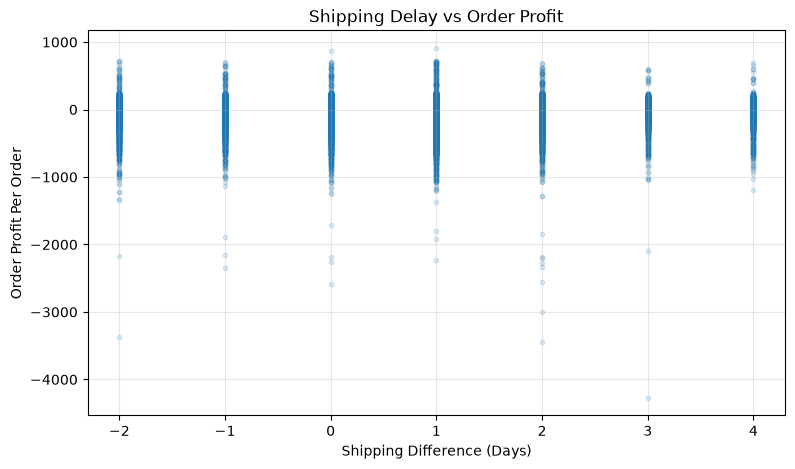

In [9]:
df["Shipping Difference"] = pd.to_numeric(
    df["Shipping Difference"], errors="coerce"
)

df["Order Profit Per Order"] = pd.to_numeric(
    df["Order Profit Per Order"], errors="coerce"
)

# Calculate the correlation between shipping delay and order profit
correlation = df[
    ["Shipping Difference", "Order Profit Per Order"]
].corr().iloc[0, 1]

print(f"Correlation between shipping difference and order profit: {correlation:.4f}")

# Group orders by delivery timing
df["Delivery Timing"] = np.select(
    [
        df["Shipping Difference"] < 0,
        df["Shipping Difference"] == 0,
        df["Shipping Difference"] > 0
    ],
    [
        "Early",
        "On Schedule",
        "Late"
    ],
    default="Unknown"
)

# Compare profit across delivery timing categories
profit_comparison = df.groupby("Delivery Timing").agg(
    Total_Orders=("Order ID", "count"),
    Average_Shipping_Difference=("Shipping Difference", "mean"),
    Average_Order_Profit=("Order Profit Per Order", "mean"),
    Median_Order_Profit=("Order Profit Per Order", "median")
).round(2)

display(profit_comparison)

# Visualise the relationship
plt.figure(figsize=(9, 5))
plt.scatter(
    df["Shipping Difference"],
    df["Order Profit Per Order"],
    alpha=0.15,
    s=10
)

plt.title("Shipping Delay vs Order Profit")
plt.xlabel("Shipping Difference (Days)")
plt.ylabel("Order Profit Per Order")
plt.grid(True, alpha=0.3)
plt.show()

###**Check data quality and inconsistencies**

In [10]:
# 1. Check for duplicate records
duplicate_rows = df.duplicated().sum()
duplicate_order_ids = df["Order ID"].duplicated().sum()

print("DATA QUALITY CHECKS")
print("-------------------")
print(f"Total records: {len(df):,}")
print(f"Duplicate rows: {duplicate_rows:,}")
print(f"Repeated Order IDs: {duplicate_order_ids:,}")


# 2. Check for missing values
print("\nMISSING VALUES BY COLUMN")
print("------------------------")
print(df.isnull().sum())


# 3. Recalculate shipping-time differences
calculated_difference = (
    df["Actual Shipping Days"] - df["Scheduled Shipping Days"]
)

difference_mismatches = (
    calculated_difference != df["Shipping Difference"]
).sum()

print("\nSHIPPING DIFFERENCE VALIDATION")
print("------------------------------")
print(
    "Records with incorrect shipping differences:",
    f"{difference_mismatches:,}"
)


# 4. Compare recorded delivery status with calculated timing
status = (
    df["Delivery Status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

calculated_timing = np.select(
    [
        calculated_difference < 0,
        calculated_difference == 0,
        calculated_difference > 0
    ],
    [
        "early",
        "on schedule",
        "late"
    ],
    default="unknown"
)

comparison_df = pd.DataFrame({
    "Recorded Status": status,
    "Calculated Timing": calculated_timing
})

print("\nRECORDED STATUS VS CALCULATED TIMING")
print("------------------------------------")
display(pd.crosstab(
    comparison_df["Recorded Status"],
    comparison_df["Calculated Timing"],
    margins=True
))


# 5. Check for potential status inconsistencies
expected_status_timing = {
    "advance shipping": "early",
    "shipping on time": "on schedule",
    "late delivery": "late"
}

expected_timing = status.map(expected_status_timing)

# Exclude statuses that cannot be assessed using this simple mapping,

assessable = expected_timing.notna()

status_mismatches = (
    assessable
    & (expected_timing != calculated_timing)
)

print("\nSTATUS CONSISTENCY CHECK")
print("------------------------")
print(
    "Records assessed:",
    f"{assessable.sum():,}"
)
print(
    "Potential status inconsistencies:",
    f"{status_mismatches.sum():,}"
)
print(
    "Statuses excluded from this comparison:",
    f"{(~assessable).sum():,}"
)

if status_mismatches.any():
    print("\nExamples of potential inconsistencies:")
    display(
        df.loc[
            status_mismatches,
            [
                "Order ID",
                "Actual Shipping Days",
                "Scheduled Shipping Days",
                "Shipping Difference",
                "Delivery Status"
            ]
        ].head(10)
    )

DATA QUALITY CHECKS
-------------------
Total records: 180,519
Duplicate rows: 60
Repeated Order IDs: 114,767

MISSING VALUES BY COLUMN
------------------------
Order ID                   0
Actual Shipping Days       0
Scheduled Shipping Days    0
Shipping Difference        0
Order Profit Per Order     0
Delivery Status            0
Shipping Mode              0
Market                     0
Order Region               0
Delivery Timing            0
dtype: int64

SHIPPING DIFFERENCE VALIDATION
------------------------------
Records with incorrect shipping differences: 0

RECORDED STATUS VS CALCULATED TIMING
------------------------------------


Calculated Timing,early,late,on schedule,All
Recorded Status,,,,
advance shipping,41592,0,0,41592
late delivery,0,98977,0,98977
shipping canceled,1774,4423,1557,7754
shipping on time,0,0,32196,32196
All,43366,103400,33753,180519



STATUS CONSISTENCY CHECK
------------------------
Records assessed: 172,765
Potential status inconsistencies: 0
Statuses excluded from this comparison: 7,754


In [14]:
duplicate_records = df[df.duplicated(keep=False)]

print(f"Rows involved in duplicate groups: {len(duplicate_records):,}")

display(
    duplicate_records.sort_values("Order ID").head(20)
)

Rows involved in duplicate groups: 120


,Order ID,Actual Shipping Days,Scheduled Shipping Days,Shipping Difference,Order Profit Per Order,Delivery Status,Shipping Mode,Market,Order Region,Delivery Timing
56633,647,3,4,-1,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
57443,647,3,4,-1,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
169892,791,2,2,0,7.500000,Shipping on time,Second Class,LATAM,South America,On Schedule
169610,791,2,2,0,7.500000,Shipping on time,Second Class,LATAM,South America,On Schedule
76821,872,3,4,-1,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
20624,872,3,4,-1,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
83568,1596,2,4,-2,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
95821,1596,2,4,-2,0.000000,Advance shipping,Standard Class,LATAM,Central America,Early
24916,2596,2,1,1,0.000000,Late delivery,First Class,LATAM,Central America,Late
24908,2596,2,1,1,0.000000,Late delivery,First Class,LATAM,Central America,Late


In [11]:
# Count exact duplicate rows, excluding the first occurrence
exact_duplicates = df.duplicated()

print("Original dataset rows:", f"{len(df):,}")
print("Exact duplicate rows:", f"{exact_duplicates.sum():,}")
print("Rows remaining if duplicates were removed:",
      f"{len(df.drop_duplicates()):,}")

Original dataset rows: 180,519
Exact duplicate rows: 60
Rows remaining if duplicates were removed: 180,459


#                                  ##**Develop delivery-performance visualisations**


                                  

In [13]:
output_folder = Path("output/charts")
output_folder.mkdir(parents=True, exist_ok=True)

# Set consistent chart styling
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Visualisation environment is ready.")
print("Chart export folder:", output_folder.resolve())

Visualisation environment is ready.
Chart export folder: C:\Users\asave\OneDrive\Desktop\SUPPLY_CHAIN_PROJECT\output\charts


##**Calculate and plot late-delivery rates**

,Total_Orders,Late_Deliveries,Late_Rate
Shipping Mode,,,
First Class,27814,26513,95.32
Second Class,35216,26987,76.63
Same Day,9737,4454,45.74
Standard Class,107752,41023,38.07


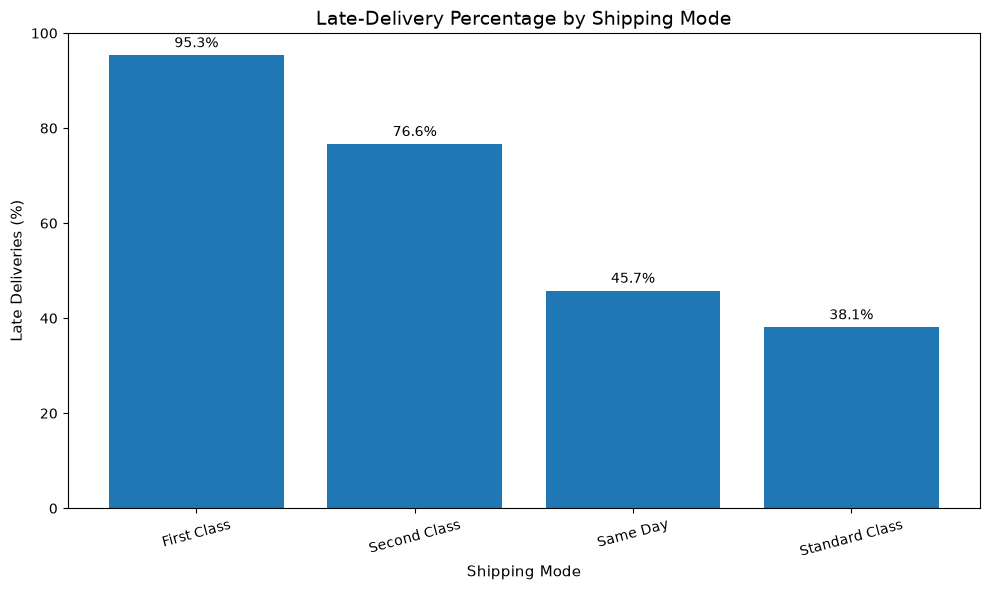

Chart 1 saved successfully.


In [14]:
# Calculate late-delivery rates by shipping mode
delivery_status = (
    df["Delivery Status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

late_flag = delivery_status.eq("late delivery")

late_by_mode = (
    df.assign(Late_Delivery=late_flag)
    .groupby("Shipping Mode")
    .agg(
        Total_Orders=("Order ID", "count"),
        Late_Deliveries=("Late_Delivery", "sum"),
        Late_Rate=("Late_Delivery", "mean")
    )
)

late_by_mode["Late_Rate"] = late_by_mode["Late_Rate"] * 100
late_by_mode = late_by_mode.sort_values("Late_Rate", ascending=False)

display(late_by_mode.round(2))

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    late_by_mode.index,
    late_by_mode["Late_Rate"]
)

plt.title("Late-Delivery Percentage by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Deliveries (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

# Display percentages above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Export the chart
plt.savefig(
    output_folder / "01_late_delivery_by_shipping_mode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 1 saved successfully.")

##**Chart actual vs scheduled shipping duration**

,Average_Actual_Days,Average_Scheduled_Days
Shipping Mode,,
Standard Class,4.00,4.0
Second Class,3.99,2.0
First Class,2.00,1.0
Same Day,0.48,0.0


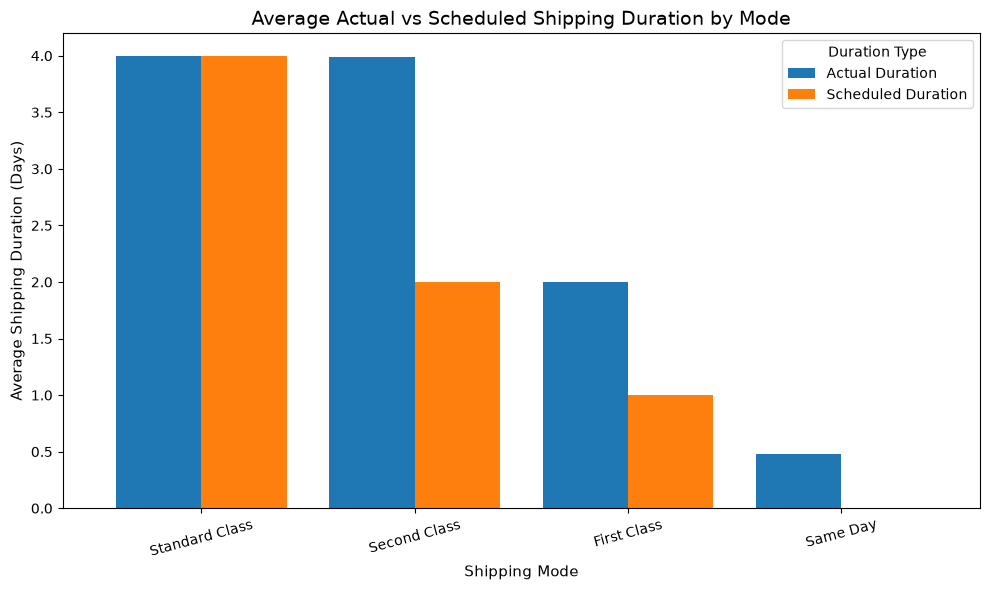

Chart 2 saved successfully.


In [15]:

duration_by_mode = (
    df.groupby("Shipping Mode")
    .agg(
        Average_Actual_Days=("Actual Shipping Days", "mean"),
        Average_Scheduled_Days=("Scheduled Shipping Days", "mean")
    )
    .sort_values("Average_Actual_Days", ascending=False)
)

display(duration_by_mode.round(2))

# Create grouped bar chart
ax = duration_by_mode.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Average Actual vs Scheduled Shipping Duration by Mode")
ax.set_xlabel("Shipping Mode")
ax.set_ylabel("Average Shipping Duration (Days)")
ax.legend(["Actual Duration", "Scheduled Duration"], title="Duration Type")
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()

# Export chart
plt.savefig(
    output_folder / "02_actual_vs_scheduled_duration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 2 saved successfully.")

##**Visualise delivery-status distributions**

,Number of Shipments
Delivery Status,
Late delivery,98977
Shipping on time,32196
Advance shipping,41592
Shipping canceled,7754


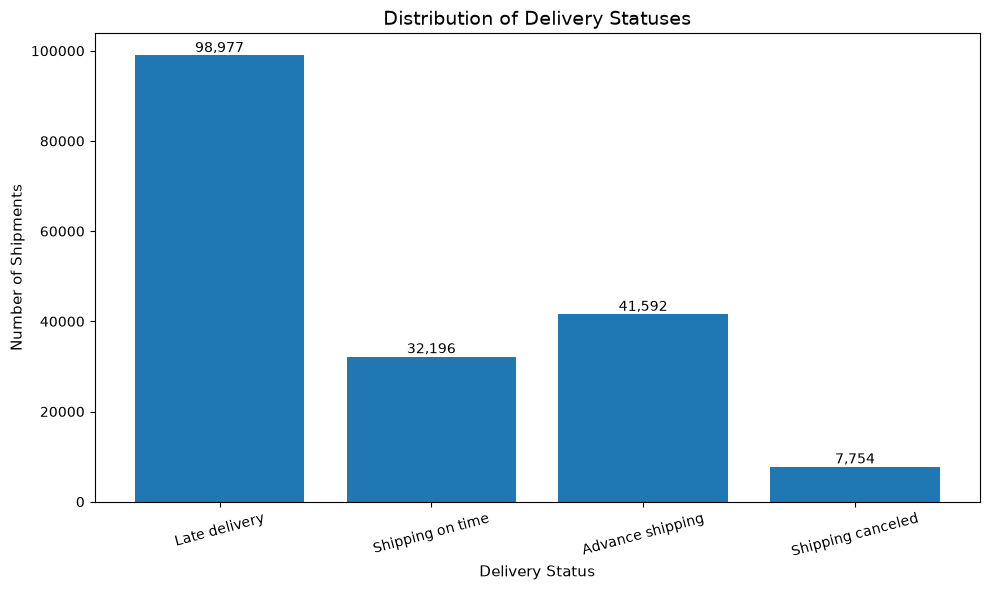

Chart 3 saved successfully.


In [16]:
# Count records in each delivery status
status_counts = (
    df["Delivery Status"]
    .astype(str)
    .str.strip()
    .value_counts()
    .reindex(
        [
            "Late delivery",
            
            "Shipping on time",
            "Advance shipping",
            "Shipping canceled"
        ],
        fill_value=0
    )
)

display(status_counts.to_frame(name="Number of Shipments"))

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(status_counts.index, status_counts.values)

plt.title("Distribution of Delivery Statuses")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=15)

# Add record counts above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Export chart
plt.savefig(
    output_folder / "03_delivery_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 3 saved successfully.")

##**Compare late-delivery rates across markets**

,Total_Orders,Late_Deliveries,Late_Rate
Market,,,
LATAM,51594,28044,54.36
Africa,11614,6340,54.59
USCA,25799,14138,54.80
Pacific Asia,41260,22712,55.05
Europe,50252,27743,55.21


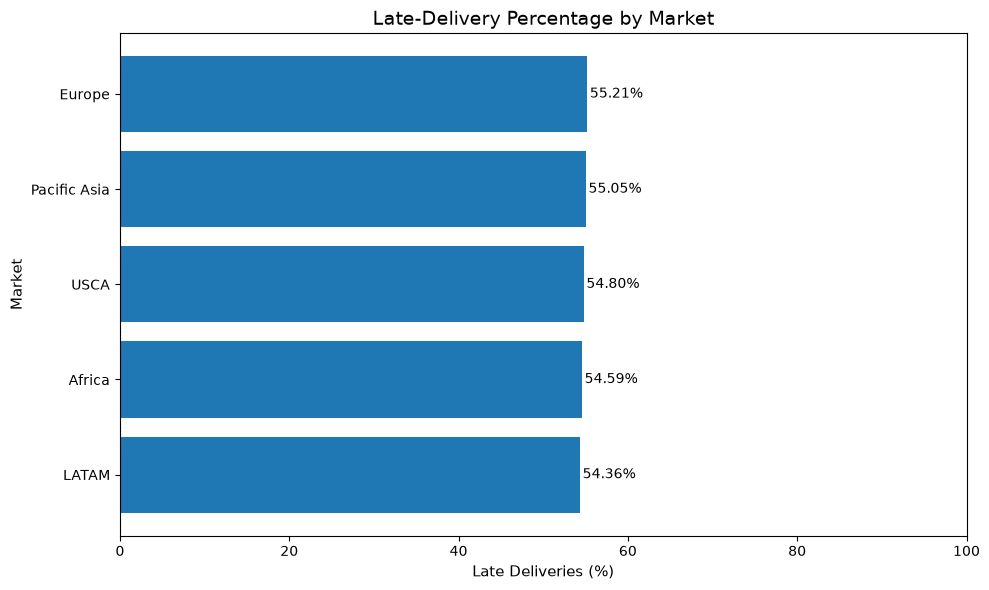

Chart 4 saved successfully.


In [17]:

market_performance = (
    df.assign(
        Is_Late=(
            df["Delivery Status"]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("late delivery")
        )
    )
    .groupby("Market")
    .agg(
        Total_Orders=("Order ID", "count"),
        Late_Deliveries=("Is_Late", "sum"),
        Late_Rate=("Is_Late", "mean")
    )
)

market_performance["Late_Rate"] *= 100

market_performance = market_performance.sort_values(
    "Late_Rate",
    ascending=True
)

display(market_performance.round(2))

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    market_performance.index,
    market_performance["Late_Rate"]
)

plt.title("Late-Delivery Percentage by Market")
plt.xlabel("Late Deliveries (%)")
plt.ylabel("Market")
plt.xlim(0, 100)

# Add percentages to the bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()

# Export chart
plt.savefig(
    output_folder / "04_late_delivery_by_market.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 4 saved successfully.")

##**Visualise shipping delays vs order profit**

Correlation between shipping difference and order profit: -0.0054


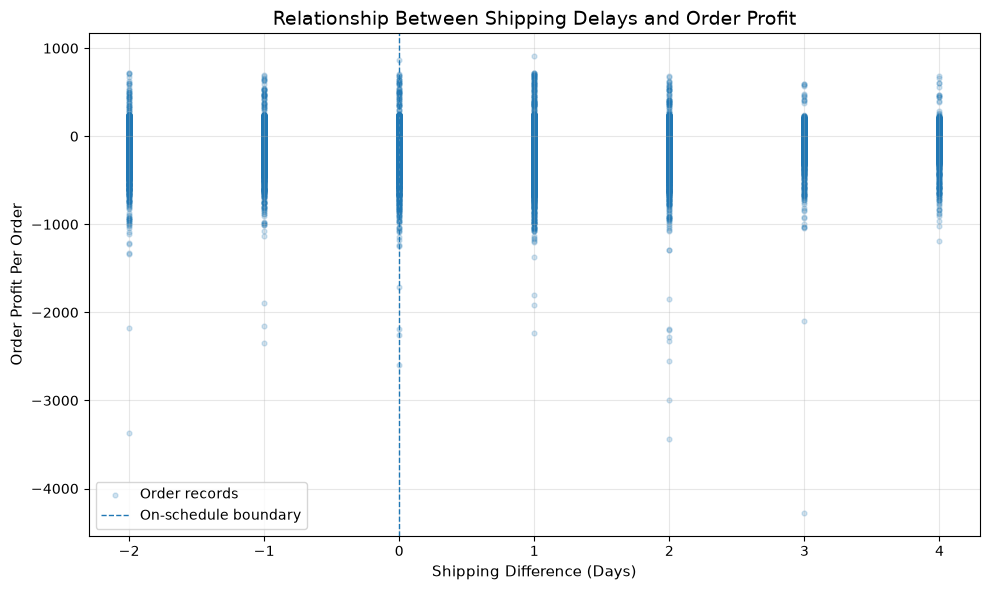

Chart 5 saved successfully.


In [18]:

shipping_difference = pd.to_numeric(
    df["Shipping Difference"],
    errors="coerce"
)

order_profit = pd.to_numeric(
    df["Order Profit Per Order"],
    errors="coerce"
)

# Keep records with valid values
profit_delay_df = pd.DataFrame({
    "Shipping Difference": shipping_difference,
    "Order Profit Per Order": order_profit
}).dropna()

# Calculate correlation
correlation = profit_delay_df[
    "Shipping Difference"
].corr(profit_delay_df["Order Profit Per Order"])

print(
    "Correlation between shipping difference and order profit:",
    f"{correlation:.4f}"
)

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    profit_delay_df["Shipping Difference"],
    profit_delay_df["Order Profit Per Order"],
    alpha=0.2,
    s=12,
    label="Order records"
)

plt.title("Relationship Between Shipping Delays and Order Profit")
plt.xlabel("Shipping Difference (Days)")
plt.ylabel("Order Profit Per Order")
plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1,
    label="On-schedule boundary"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Export chart
plt.savefig(
    output_folder / "05_shipping_delay_vs_order_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 5 saved successfully.")

In [24]:

chart_files = sorted(output_folder.glob("*.png"))

print(f"Number of exported charts: {len(chart_files)}")

for chart_file in chart_files:
    print(chart_file.name, "-", f"{chart_file.stat().st_size:,} bytes")

Number of exported charts: 5
01_late_delivery_by_shipping_mode.png - 130,499 bytes
02_actual_vs_scheduled_duration.png - 151,830 bytes
03_delivery_status_distribution.png - 134,060 bytes
04_late_delivery_by_market.png - 109,257 bytes
05_shipping_delay_vs_order_profit.png - 215,465 bytes


#                                                  ##** Validate the findings and prepare recommendations**

In [19]:
# Select one record for each delivery timing
manual_check = (
    df.groupby("Delivery Timing", group_keys=False)
    .head(1)
)

# Keep the three timing categories we want to verify
manual_check = manual_check[
    manual_check["Delivery Timing"].isin(
        ["Early", "On Schedule", "Late"]
    )
].copy()

# Recalculate the shipping difference independently
manual_check["Manually Calculated Difference"] = (
    manual_check["Actual Shipping Days"]
    - manual_check["Scheduled Shipping Days"]
)

manual_check["Calculation Matches"] = (
    manual_check["Manually Calculated Difference"]
    == manual_check["Shipping Difference"]
)

display(
    manual_check[
        [
            "Order ID",
            "Actual Shipping Days",
            "Scheduled Shipping Days",
            "Shipping Difference",
            "Manually Calculated Difference",
            "Delivery Timing",
            "Calculation Matches"
        ]
    ]
)

,Order ID,Actual Shipping Days,Scheduled Shipping Days,Shipping Difference,Manually Calculated Difference,Delivery Timing,Calculation Matches
0,77202,3,4,-1,-1,Early,True
1,75939,5,4,1,1,Late,True
2,75938,4,4,0,0,On Schedule,True


In [21]:
# Reload the CSV exported by Java
verification_df = pd.read_csv("processed_orders.csv")

# Recalculate key delivery metrics
status = (
    verification_df["Delivery Status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

total_records = len(verification_df)
late_count = status.eq("late delivery").sum()
late_percentage = late_count / total_records * 100

average_actual = verification_df["Actual Shipping Days"].mean()
average_scheduled = verification_df["Scheduled Shipping Days"].mean()

average_difference = (
    verification_df["Shipping Difference"].mean()
)

print("PYTHON VALIDATION RESULTS")
print("-------------------------")
print(f"Total records: {total_records:,}")
print(f"Late deliveries: {late_count:,}")
print(f"Late-delivery percentage: {late_percentage:.2f}%")
print(f"Average actual shipping days: {average_actual:.2f}")
print(f"Average scheduled shipping days: {average_scheduled:.2f}")
print(f"Average shipping difference: {average_difference:.2f}")

PYTHON VALIDATION RESULTS
-------------------------
Total records: 180,519
Late deliveries: 98,977
Late-delivery percentage: 54.83%
Average actual shipping days: 3.50
Average scheduled shipping days: 2.93
Average shipping difference: 0.57


##**Document data-quality issues and limitations**

In [22]:
# Summarise data-quality findings
quality_summary = pd.DataFrame({
    "Validation Check": [
        "Total records",
        "Exact duplicate rows",
        "Missing values",
        "Shipping difference mismatches",
        "Potential status inconsistencies",
        "Cancelled shipments excluded from status comparison"
    ],
    "Result": [
        f"{len(df):,}",
        f"{df.duplicated().sum():,}",
        f"{int(df.isnull().sum().sum()):,}",
        f"{(
            df['Actual Shipping Days']
            - df['Scheduled Shipping Days']
            != df['Shipping Difference']
        ).sum():,}",
        f"{int(status_mismatches.sum()):,}",
        f"{int((status == 'shipping canceled').sum()):,}"
    ]
})

display(quality_summary)

,Validation Check,Result
0,Total records,"180,519"
1,Exact duplicate rows,60
2,Missing values,0
3,Shipping difference mismatches,0
4,Potential status inconsistencies,0
5,Cancelled shipments excluded from status compa...,"7,754"


##**Identify shipping methods and markets needing investigation**

In [23]:
# Rank shipping modes by late-delivery percentage
mode_investigation = (
    late_by_mode[
        ["Total_Orders", "Late_Deliveries", "Late_Rate"]
    ]
    .sort_values("Late_Rate", ascending=False)
)

print("SHIPPING MODES — HIGHEST LATE-DELIVERY RATES")
display(mode_investigation.round(2))

# Rank markets by late-delivery percentage
market_investigation = (
    market_performance[
        ["Total_Orders", "Late_Deliveries", "Late_Rate"]
    ]
    .sort_values("Late_Rate", ascending=False)
)

print("MARKETS — HIGHEST LATE-DELIVERY RATES")
display(market_investigation.round(2))

SHIPPING MODES — HIGHEST LATE-DELIVERY RATES


,Total_Orders,Late_Deliveries,Late_Rate
Shipping Mode,,,
First Class,27814,26513,95.32
Second Class,35216,26987,76.63
Same Day,9737,4454,45.74
Standard Class,107752,41023,38.07


MARKETS — HIGHEST LATE-DELIVERY RATES


,Total_Orders,Late_Deliveries,Late_Rate
Market,,,
Europe,50252,27743,55.21
Pacific Asia,41260,22712,55.05
USCA,25799,14138,54.80
Africa,11614,6340,54.59
LATAM,51594,28044,54.36


#                                 ##**Record the key metrics for the report**

In [25]:
# Key operational metrics for the technical report

report_metrics = pd.DataFrame({
    "Metric": [
        "Total records processed",
        "Late deliveries",
        "Late-delivery percentage",
        "Average actual shipping duration",
        "Average scheduled shipping duration",
        "Average shipping difference",
        "Exact duplicate rows",
        "Missing values",
        "Shipping difference mismatches"
    ],
    "Value": [
        f"{len(verification_df):,}",
        f"{late_count:,}",
        f"{late_percentage:.2f}%",
        f"{average_actual:.2f} days",
        f"{average_scheduled:.2f} days",
        f"{average_difference:.2f} days",
        f"{df.duplicated().sum():,}",
        f"{int(df.isnull().sum().sum()):,}",
        f"{(
            df['Actual Shipping Days']
            - df['Scheduled Shipping Days']
            != df['Shipping Difference']
        ).sum():,}"
    ]
})

display(report_metrics)

# Save the summary for future reference
report_metrics.to_csv(
    output_folder / "task4_key_metrics.csv",
    index=False
)

print(" metrics summary saved.")

,Metric,Value
0,Total records processed,"180,519"
1,Late deliveries,"98,977"
2,Late-delivery percentage,54.83%
3,Average actual shipping duration,3.50 days
4,Average scheduled shipping duration,2.93 days
5,Average shipping difference,0.57 days
6,Exact duplicate rows,60
7,Missing values,0
8,Shipping difference mismatches,0


 metrics summary saved.


#                         ##**END**